# Test accuracy vs. noise variance

Reads the result spreadsheets written by the noise-sweep notebooks and plots test accuracy against noise variance, one panel per model.

Nothing below is hardcoded to a particular run:

* Each model folder (`lenet5_mnist`, `resnet20_cifar10`, `mobilenetv1_tinyimagenet`) is scanned for `results_*` sub-folders and the **newest** `.xlsx` in each one is loaded (sheet `long`).
* Method labels are taken from the `method` column. Trailing run details such as `(T=1.0,10ep)` are stripped so that e.g. `LMC-SPSA(T=1.0,200ep)` and `LMC-SPSA(T=1.0,300ep)` map to the same curve.
* The baseline rows (`Full retrain`, `Init (no retrain)`) are repeated in several files; they are taken from the BOLSTER file when it exists.
* If a method has several seeds per noise level, the mean is plotted and ±1 std is shaded.

Run it from the `plots/` folder (or anywhere inside the project).

In [154]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [155]:
FONT_FAMILY         = "DejaVu Sans"   # e.g. "serif", "Times New Roman", "Arial", ...
BASE_FONTSIZE       = 25              # default text size (titles, legend title, ...)
AXIS_LABEL_FONTSIZE = 17              # x/y axis label size
AXIS_TICK_FONTSIZE  = 17              # x/y tick label size
plt.rcParams.update({
    "font.family":     FONT_FAMILY,
    "font.size":       BASE_FONTSIZE,
    "axes.labelsize":  AXIS_LABEL_FONTSIZE,
    "axes.titlesize":  BASE_FONTSIZE + 1,
    "xtick.labelsize": AXIS_TICK_FONTSIZE,
    "ytick.labelsize": AXIS_TICK_FONTSIZE,
    "legend.fontsize": BASE_FONTSIZE - 3,
})

## Configuration

Only presentation choices live here (which folders become panels, how labels are displayed, colours, axis limits). All numbers come from the spreadsheets.

In [156]:
# Model folder -> panel title. The order here is the subplot order.
# Leave empty ({}) to auto-discover every folder under the project root that contains results_* sub-folders.
MODELS = {
    "lenet5_mnist":             "LeNet5/MNIST",
    "resnet20_cifar10":         "ResNet20/CIFAR10",
    "mobilenetv1_tinyimagenet": "MobileNet-v1/Tiny ImageNet",
}

# Optional y-limits per panel; panels not listed use automatic limits.
YLIMS = {
    "lenet5_mnist":             (0.6, 1.0),
    "resnet20_cifar10":         (0.0, 1.0),
    "mobilenetv1_tinyimagenet": (0.0, 0.6),
}

RESULTS_DIR_GLOB = "results_*"   # sub-folders of each model folder that hold the xlsx files
SHEET_NAME       = "long"        # sheet with one row per (noise_level, method[, seed])
METRIC           = "accuracy"    # column to plot

# Label in the xlsx `method` column -> legend label. Trailing parentheses such as "(T=1.0,10ep)"
# are stripped before the lookup, so "LMC-SPSA(T=1.0,200ep)" matches the "LMC-SPSA" entry.
# Labels that are not listed are shown as they appear in the file.
DISPLAY_NAMES = {
    "Full retrain":      "Backpropagation",
    "Init (no retrain)": "No retrain",
    "BOLSTER":           "Ours",
    "LMC-SPSA":          "LMC",
    "Sparse-MeZO":       "SMEZO",
}
EXCLUDE_METHODS = {"BP-FC"}      # xlsx labels (after stripping) that should not be plotted

# The baseline rows (Full retrain / Init (no retrain) / ...) are written into several result files.
# When a method is reported by more than one results_* folder, the curve is taken from this one if present.
PREFERRED_SOURCE = "bolster"

# Legend order (display names). Methods not listed are appended alphabetically.
PLOT_ORDER = ["Backpropagation", "No retrain", "SCFF", "PEPITA", "SMEZO", "LMC", "Ours"]
# Colour per method (display names). Methods not listed take the next colour of the matplotlib cycle.
COLORS = {
    "Ours":            "tab:green",
    "Backpropagation": "tab:blue",
    "No retrain":      "black",
    "SCFF":            "tab:red",
    "PEPITA":          "tab:orange",
    "SMEZO":           "tab:purple",
    "LMC":             "tab:gray",
}
LINE_STYLE = {}   # optional extra per-method kwargs for plt.plot, e.g. {"Ours": {"linewidth": 2.5}}

OUTPUT_FILE = Path("figures") / "accuracy_comparison.png"

## Locate and load the result spreadsheets

In [157]:
def find_project_root(start: Path = Path.cwd()) -> Path:
    """Walk up from `start` until a folder is found whose children contain results_* folders."""
    for candidate in (start, *start.parents):
        if any(p.is_dir() for p in candidate.glob(f"*/{RESULTS_DIR_GLOB}")):
            return candidate
    raise FileNotFoundError(f"No '*/{RESULTS_DIR_GLOB}' folders found in {start} or its parents")


def discover_models(root: Path) -> dict:
    """Return {model_folder: panel_title}. Uses MODELS if given, otherwise every folder with results_* inside."""
    if MODELS:
        return dict(MODELS)
    found = sorted({p.parent.name for p in root.glob(f"*/{RESULTS_DIR_GLOB}") if p.is_dir()})
    return {name: name for name in found}


_TIMESTAMP_RE = re.compile(r"(\d{8}_\d{6})")

def latest_xlsx(results_dir: Path):
    """Newest .xlsx in a results_* folder: by the YYYYMMDD_HHMMSS stamp in the name, else by mtime."""
    files = [f for f in results_dir.glob("*.xlsx") if not f.name.startswith("~$")]
    if not files:
        return None
    def sort_key(f):
        m = _TIMESTAMP_RE.search(f.stem)
        return (m.group(1) if m else "", f.stat().st_mtime)
    return max(files, key=sort_key)


def source_from_dir(results_dir: Path, model_dir: str) -> str:
    """'results_lmc_spsa_resnet20_cifar10' with model 'resnet20_cifar10' -> 'lmc_spsa'."""
    name = results_dir.name
    if name.startswith("results_"):
        name = name[len("results_"):]
    suffix = f"_{model_dir}"
    if name.endswith(suffix):
        name = name[: -len(suffix)]
    return name


def load_results(root: Path, models: dict) -> pd.DataFrame:
    frames = []
    for model_dir in models:
        mdir = root / model_dir
        if not mdir.is_dir():
            print(f"[warn] model folder not found: {mdir}")
            continue
        for rdir in sorted(p for p in mdir.glob(RESULTS_DIR_GLOB) if p.is_dir()):
            f = latest_xlsx(rdir)
            if f is None:
                print(f"[warn] no .xlsx in {rdir.relative_to(root)}")
                continue
            df = pd.read_excel(f, sheet_name=SHEET_NAME)
            missing = {"noise_level", "method", METRIC} - set(df.columns)
            if missing:
                print(f"[warn] {f.relative_to(root)} lacks columns {sorted(missing)}; skipped")
                continue
            source = source_from_dir(rdir, model_dir)
            df["model"]  = model_dir
            df["source"] = source
            df["file"]   = str(f.relative_to(root))
            frames.append(df)
            print(f"{model_dir:26s} {source:12s} <- {f.relative_to(root)}  ({len(df)} rows)")
    if not frames:
        raise FileNotFoundError("No result spreadsheets were loaded")
    return pd.concat(frames, ignore_index=True)


PROJECT_ROOT = find_project_root()
models = discover_models(PROJECT_ROOT)
print(f"project root: {PROJECT_ROOT}\n")
raw = load_results(PROJECT_ROOT, models)

project root: /home/rahman2/GIT/BOLSTER

lenet5_mnist               bolster      <- lenet5_mnist/results_bolster_lenet5_mnist/results_bolster_lenet5_mnist_20261007_143254.xlsx  (40 rows)
lenet5_mnist               lmc_spsa     <- lenet5_mnist/results_lmc_spsa_lenet5_mnist/results_lmc_spsa_lenet5_mnist_20261007_150417.xlsx  (40 rows)
lenet5_mnist               pepita       <- lenet5_mnist/results_pepita_lenet5_mnist/results_pepita_lenet5_mnist_20261007_134721.xlsx  (20 rows)
lenet5_mnist               scff         <- lenet5_mnist/results_scff_lenet5_mnist/results_scff_lenet5_mnist_20260930_020107.xlsx  (20 rows)
lenet5_mnist               smezo_spsa   <- lenet5_mnist/results_smezo_spsa_lenet5_mnist/results_smezo_spsa_lenet5_mnist_20261007_145236.xlsx  (40 rows)
resnet20_cifar10           bolster      <- resnet20_cifar10/results_bolster_resnet20_cifar10/results_bolster_resnet20_cifar10_20261007_135331.xlsx  (40 rows)
resnet20_cifar10           lmc_spsa     <- resnet20_cifar10/results_lmc

## Normalise labels and pick one source per curve

In [158]:
_SUFFIX_RE = re.compile(r"\s*\([^()]*\)\s*$")   # trailing "(...)" e.g. "(T=1.0,10ep)"

def base_method(label) -> str:
    """Strip the trailing run details unless the full label is itself a known name."""
    label = str(label).strip()
    if label in DISPLAY_NAMES or label in EXCLUDE_METHODS:
        return label
    stripped = _SUFFIX_RE.sub("", label)
    return stripped or label


def parse_noise(value) -> float:
    """'10%' -> 0.1 ; 0.1 -> 0.1"""
    if isinstance(value, str) and value.strip().endswith("%"):
        return float(value.strip()[:-1]) / 100.0
    return float(value)


df = raw.copy()
df["method_base"] = df["method"].map(base_method)
df["method_name"] = df["method_base"].map(lambda b: DISPLAY_NAMES.get(b, b))
df["noise"]       = df["noise_level"].map(parse_noise)
df = df[~df["method_base"].isin(EXCLUDE_METHODS)]

# A method that appears in several results_* folders (the baselines) is taken from PREFERRED_SOURCE
# when that folder reports it, otherwise from the first folder (alphabetically) that does.
priority = (df["source"] != PREFERRED_SOURCE).astype(int)
chosen = (df.assign(_prio=priority)
            .sort_values(["_prio", "source"])
            .groupby(["model", "method_name"])["source"].first()
            .rename("chosen_source"))
df = df.join(chosen, on=["model", "method_name"])
df = df[df["source"] == df["chosen_source"]].drop(columns="chosen_source")

# Mean / std over seeds (if any) per (model, method, noise level)
acc = (df.groupby(["model", "method_name", "noise"])[METRIC]
         .agg(mean="mean", std="std", n="count")
         .reset_index())

print("Curve sources:")
print(chosen.unstack("method_name").fillna("-").to_string(), "\n")

for model_dir, title in models.items():
    table = acc[acc["model"] == model_dir].pivot(index="noise", columns="method_name", values="mean")
    if table.empty:
        continue
    cols = [m for m in PLOT_ORDER if m in table.columns] + sorted(set(table.columns) - set(PLOT_ORDER))
    print(f"== {title} ({METRIC}, mean over {int(acc[acc['model'] == model_dir]['n'].max())} run(s))")
    print(table[cols].round(4).to_string(), "\n")

Curve sources:
method_name              Backpropagation       LMC No retrain     Ours  PEPITA  SCFF       SMEZO
model                                                                                           
lenet5_mnist                     bolster  lmc_spsa    bolster  bolster  pepita  scff  smezo_spsa
mobilenetv1_tinyimagenet         bolster  lmc_spsa    bolster  bolster  pepita  scff  smezo_spsa
resnet20_cifar10                 bolster  lmc_spsa    bolster  bolster  pepita  scff  smezo_spsa 

== LeNet5/MNIST (accuracy, mean over 1 run(s))
method_name  Backpropagation  No retrain    SCFF  PEPITA   SMEZO     LMC    Ours
noise                                                                           
0.1                   0.9761      0.9677  0.9471  0.9648  0.9677  0.9674  0.9677
0.2                   0.9748      0.9640  0.9236  0.9593  0.9638  0.9625  0.9646
0.3                   0.9734      0.9585  0.8844  0.9519  0.9583  0.9588  0.9600
0.4                   0.9722      0.9524  0.84

## Plot

saved /home/rahman2/GIT/BOLSTER/plots/figures/accuracy_comparison.png


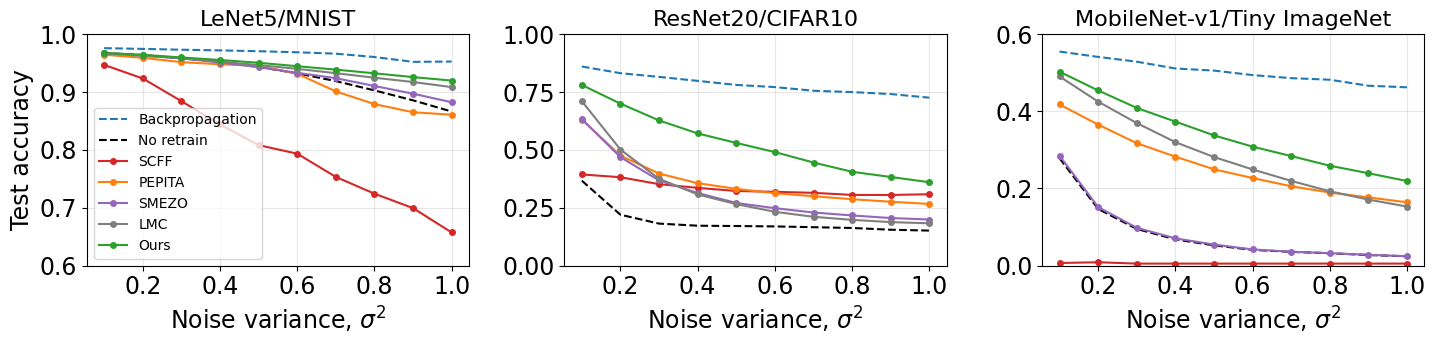

In [159]:
def ordered_methods(names) -> list:
    names = set(names)
    return [m for m in PLOT_ORDER if m in names] + sorted(names - set(PLOT_ORDER))

# One colour per method, shared by all panels, so curves stay comparable even when a method is missing from a panel.
all_methods = ordered_methods(acc["method_name"].unique())
cycle = iter(plt.rcParams["axes.prop_cycle"].by_key()["color"] * 10)
colors = {m: COLORS.get(m) or next(cycle) for m in all_methods}

n_panels = len(models)
fig, axes = plt.subplots(1, n_panels, figsize=(5 * n_panels, 4), squeeze=False)

for ax, (model_dir, title) in zip(axes[0], models.items()):
    panel = acc[acc["model"] == model_dir]
    for m in ordered_methods(panel["method_name"].unique()):
        s = panel[panel["method_name"] == m].sort_values("noise")
        style = {"marker": "o", "color": colors[m], "markersize": 4, **LINE_STYLE.get(m, {})}

        # Dashed lines for Backpropagation and No retrain
        if m.lower() in ["backpropagation", "no retrain"]:
            style["linestyle"] = "--"
            style["marker"] = None

        ax.plot(s["noise"], s["mean"], label=m, **style)
        if (s["n"] > 1).any():   # several seeds -> shade +/- 1 std
            ax.fill_between(s["noise"], s["mean"] - s["std"].fillna(0), s["mean"] + s["std"].fillna(0),
                            color=style["color"], alpha=0.15, linewidth=0)
    ax.set_title(title,fontsize=16)
    ax.set_xlabel(r"Noise variance, $\sigma^2$")
    if model_dir in YLIMS:
        ax.set_ylim(*YLIMS[model_dir])
    ax.grid(True, alpha=0.3)

axes[0][0].set_ylabel("Test accuracy")
axes[0][0].legend(fontsize=10)

fig.tight_layout()
OUTPUT_FILE.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(OUTPUT_FILE, dpi=300, bbox_inches="tight")
print(f"saved {OUTPUT_FILE.resolve()}")
plt.show()